In [1]:
import pandas as pd

# 1. Memuat dataset
df = pd.read_csv('../data/heart_disease_uci.csv')

# 2. Membuat kolom 'target' (karena di kode heatmap Anda memanggil kolom 'target')
df['target'] = (df['num'] > 0).astype(int)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Hilangkan warning
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv('../data/heart_disease_uci.csv')
print("Dataset berhasil dimuat!")
display(df.head())

In [ ]:
print("="*50)
print("1. MENELAAH DATA")
print("="*50)
# Menampilkan info seperti PDF Hal 5
df.info()

print("\n" + "="*50)
print("2. MEMVALIDASI DATA (Cek Inf & Null)")
print("="*50)
# Cek nilai Inf (seperti PDF Hal 6)
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
print(f"Jumlah nilai Inf pada kolom numerik: {np.isinf(df[num_cols]).sum().sum()}")

# Cek Null (seperti PDF Hal 7)
print("\nJumlah Missing Values (Null) per kolom:")
print(df.isnull().sum()[df.isnull().sum() > 0])

1. MENELAAH DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB

2. MEMVALIDASI DATA (Cek Inf & Null)
Jumlah nilai Inf pada kolom numerik: 0

Jumlah Missing Values (Null) per k

In [ ]:
print("="*50)
print("3. MENENTUKAN OBJEK & LABEL")
print("="*50)

# Menampilkan 5 baris objek data (seperti PDF Hal 8)
print("Contoh Objek Data (5 Baris Pertama):")
display(df.head())

# Menentukan Label (Seperti PDF Hal 11, memetakan label)
# Target asli 'num' (0-4), kita ubah ke binary (0=Normal, 1=Sakit)
df['Category'] = df['num'].apply(lambda x: 'NORMAL' if x == 0 else 'SAKIT JANTUNG')

print("\nDistribusi Label Kategori:")
print(df['Category'].value_counts())

3. MENENTUKAN OBJEK & LABEL
Contoh Objek Data (5 Baris Pertama):


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0



Distribusi Label Kategori:
Category
SAKIT JANTUNG    509
NORMAL           411
Name: count, dtype: int64


4. VISUALISASI DISTRIBUSI KATEGORI


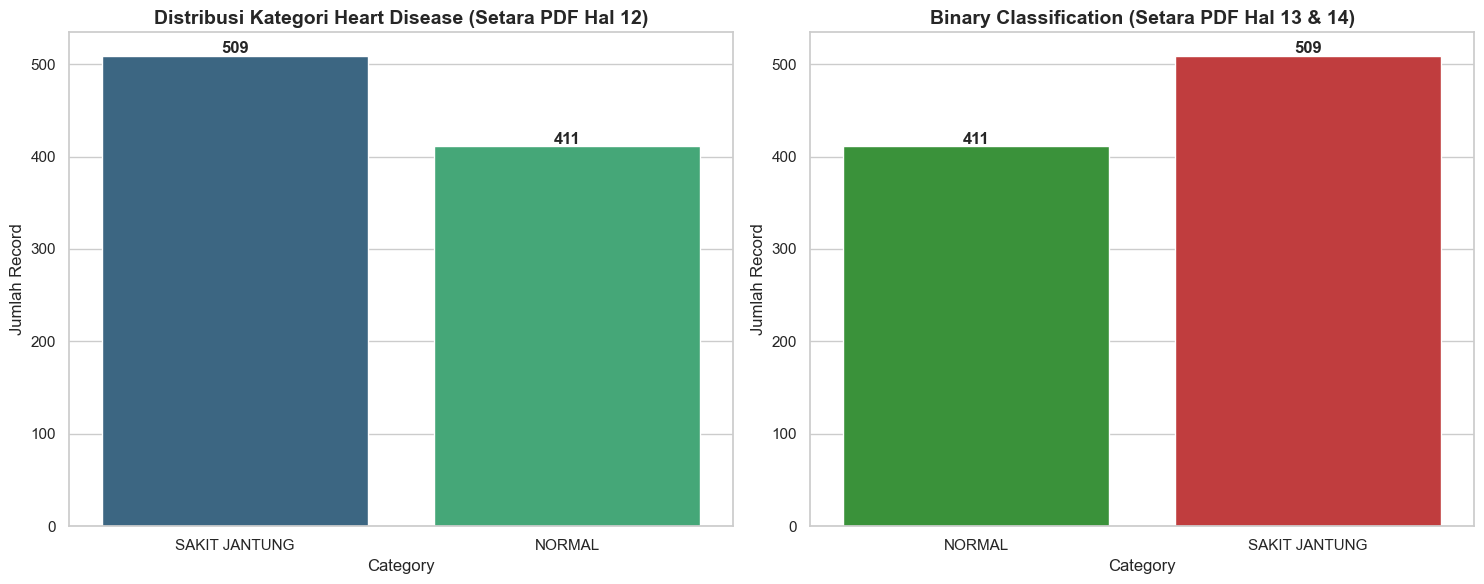

In [ ]:
print("="*50)
print("4. VISUALISASI DISTRIBUSI KATEGORI")
print("="*50)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Grafik 1: Distribusi Kategori (Setara PDF Hal 12)
sns.countplot(ax=axes[0], data=df, x='Category', order=df['Category'].value_counts().index, palette='viridis')
axes[0].set_title('Distribusi Kategori Heart Disease (Setara PDF Hal 12)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Jumlah Record')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# Grafik 2: Binary Classification (Setara PDF Hal 13 & 14)
# Karena dataset kita hanya punya 2 kelas (Normal & Sakit), grafiknya sama saja, tapi kita buat lebih tegas
sns.countplot(ax=axes[1], data=df, x='Category', palette=['#2ca02c', '#d62728'])
axes[1].set_title('Binary Classification (Setara PDF Hal 13 & 14)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Jumlah Record')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
print("="*50)
print("5. MEMBERSIHKAN DATA")
print("="*50)

# 1. Konversi Inf ke NaN (Seperti PDF Hal 17)
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2. Imputasi Nilai Kosong
# Untuk numerik pakai median (Seperti PDF Hal 19)
for col in ['trestbps', 'chol', 'thalch', 'oldpeak', 'ca']:
    df[col] = df[col].fillna(df[col].median())

# Untuk kategorikal pakai modus
for col in ['fbs', 'restecg', 'exang', 'slope', 'thal', 'cp']:
    df[col] = df[col].fillna(df[col].mode()[0])

# Cek ulang null
print(f"Sisa Missing Values setelah imputasi: {df.isnull().sum().sum()}")

# 3. Cek & Hapus Duplikat (Seperti PDF Hal 20-21)
duplikat = df.duplicated().sum()
print(f"Total baris duplikat ditemukan: {duplikat}")
df.drop_duplicates(inplace=True)
print(f"Data setelah dihapus duplikat: {df.shape}")

5. MEMBERSIHKAN DATA
Sisa Missing Values setelah imputasi: 0
Total baris duplikat ditemukan: 0
Data setelah dihapus duplikat: (920, 17)


In [ ]:
print("="*50)
print("6. MENGKONSTRUKSI DATA")
print("="*50)

# 1. Encoding (Seperti PDF Hal 24)
# Konversi boolean/string ke angka dulu agar bisa di-encode
df['sex'] = df['sex'].map({'Male': 1, 'Female': 0})
df['fbs'] = df['fbs'].map({'TRUE': 1, 'FALSE': 0})
df['exang'] = df['exang'].map({'TRUE': 1, 'FALSE': 0})

# One Hot Encoding
df_encoded = pd.get_dummies(df, columns=['cp', 'restecg', 'slope', 'thal'], drop_first=True, dtype=int)
print(f"Shape setelah encoding: {df_encoded.shape}")

# 2. Label Target biner (Seperti PDF Hal 25)
df_encoded['Target'] = (df_encoded['num'] > 0).astype(int)

# 3. Drop kolom yang tidak dipakai & Tentukan X, y (Seperti PDF Hal 26)
X = df_encoded.drop(columns=['id', 'dataset', 'num', 'Category', 'Target'])
y = df_encoded['Target']

# 4. Seleksi Fitur via Korelasi (Seperti PDF Hal 27-28)
korelasi_target = X.corrwith(y).abs().sort_values(ascending=False)
print("\nNilai Korelasi Fitur terhadap Target:")
display(korelasi_target.head(10)) # Tampilkan 10 teratas

# Ambil fitur dengan korelasi >= 0.20 (Seperti PDF Hal 28)
fitur_penting = korelasi_target[korelasi_target >= 0.20].index.tolist()
X_baru = X[fitur_penting]

print(f"\nJumlah fitur dipakai: {len(fitur_penting)}")
print(f"Fitur terpilih: {fitur_penting}")
display(X_baru.head())

6. MENGKONSTRUKSI DATA
Shape setelah encoding: (920, 22)

Nilai Korelasi Fitur terhadap Target:


cp_atypical angina        0.403465
thalch                    0.381864
oldpeak                   0.366138
sex                       0.307284
thal_normal               0.286196
age                       0.282700
thal_reversable defect    0.257029
chol                      0.228976
cp_non-anginal            0.209812
slope_upsloping           0.180903
dtype: float64


Jumlah fitur dipakai: 9
Fitur terpilih: ['cp_atypical angina', 'thalch', 'oldpeak', 'sex', 'thal_normal', 'age', 'thal_reversable defect', 'chol', 'cp_non-anginal']


,cp_atypical angina,thalch,oldpeak,sex,thal_normal,age,thal_reversable defect,chol,cp_non-anginal
0,0,150.0,2.3,1,0,63,0,233.0,0
1,0,108.0,1.5,1,1,67,0,286.0,0
2,0,129.0,2.6,1,0,67,1,229.0,0
3,0,187.0,3.5,1,1,37,0,250.0,1
4,1,172.0,1.4,0,1,41,0,204.0,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

print("="*50)
print("7. MEMBANGUN MODEL")
print("="*50)

# 1. Split Data 80/20 (Seperti PDF Hal 29)
X_train, X_test, y_train, y_test = train_test_split(
    X_baru, y, test_size=0.2, random_state=42, stratify=y
)
print("Data berhasil dibagi menjadi set Training dan Testing.")

# 2. Standarisasi (Seperti PDF Hal 30)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Training Logistic Regression (Seperti PDF Hal 31)
log_reg = LogisticRegression(
    class_weight='balanced', solver='liblinear', random_state=42, max_iter=1000
)
log_reg.fit(X_train_scaled, y_train)
print("Pelatihan model Regresi Logistik selesai. Model siap dievaluasi.")

7. MEMBANGUN MODEL
Data berhasil dibagi menjadi set Training dan Testing.
Pelatihan model Regresi Logistik selesai. Model siap dievaluasi.


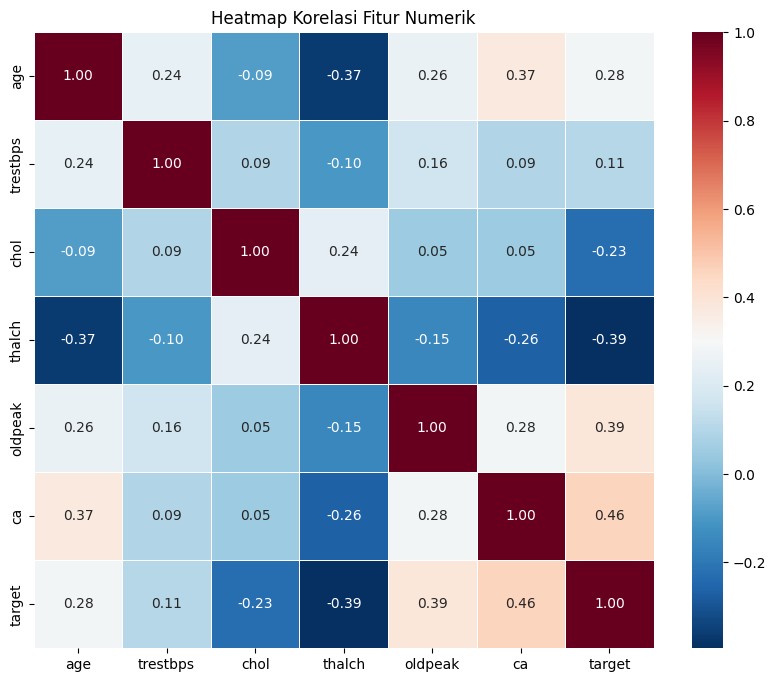

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cek korelasi antar fitur numerik
plt.figure(figsize=(10, 8))
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'target']
corr_matrix = df[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt=".2f", linewidths=.5)
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

8. EVALUASI MODEL
### Classification Report ###
              precision    recall  f1-score   support

  NORMAL (0)       0.85      0.77      0.81        82
   SAKIT (1)       0.83      0.89      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184



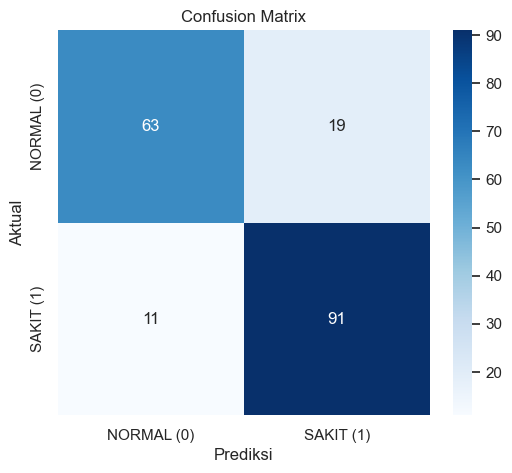

In [ ]:
from sklearn.metrics import roc_auc_score

print("="*50)
print("8. EVALUASI MODEL")
print("="*50)

# Prediksi (Tebakan Kelas)
y_pred = log_reg.predict(X_test_scaled)

# 1. Classification Report (Seperti PDF Hal 32)
print("### Classification Report ###")
print(classification_report(y_test, y_pred, target_names=['NORMAL (0)', 'SAKIT (1)']))

# --- TAMBAHAN: Hitung ROC-AUC ---
# Menggunakan probabilitas (predict_proba) bukan prediksi biner
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)
print(f"\nROC-AUC Score: {roc_auc:.2%}")
# --------------------------------

# 2. Confusion Matrix (Seperti PDF Hal 33)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['NORMAL (0)', 'SAKIT (1)'], 
            yticklabels=['NORMAL (0)', 'SAKIT (1)'])
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [ ]:
import joblib

print("="*50)
print("9. EXPORT MODEL")
print("="*50)

joblib.dump(log_reg, "../models/logreg_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(fitur_penting, "../models/features.pkl")

print("Model berhasil di-export:")
print("- logreg_model.pkl")
print("- scaler.pkl")
print("- features.pkl")

9. EXPORT MODEL
Model berhasil di-export:
- logreg_model.pkl
- scaler.pkl
- features.pkl
